<a href="https://colab.research.google.com/github/Praveen27T/DL_Cat2/blob/main/hinglish.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

print(os.listdir("/content"))

['.config', 'test.txt', 'train.txt', 'dev.txt', 'sample_data']


In [ ]:
import pandas as pd

# Loading train.txt. Since it might be tab-separated or structured differently, we read it with default settings first.
# If it is tab-separated, we can specify sep='\t'.
train_df = pd.read_csv('/content/train.txt', sep='\t', header=None, names=['text', 'label'], on_bad_lines='skip')

display(train_df.head())

,text,label
0,Batman vs Superman,batman vs superman
1,"The director is Zack Snyder , 27 % Rotten Toma...","Zack Snyder director हैं , 27 % Rotten Tomatoe..."
2,Not very popular it seems,लगता है बहुत popular नहीं है
3,But the audiences liked it . It has a B cinema...,"but audience ने like किया , इसका cinema score ..."
4,Yes,yes


In [ ]:
# Inspect the structure and quick statistics of the loaded dataset
print("Dataset Info:")
print(train_df.info())

print("\nMissing values:")
print(train_df.isnull().sum())

print("\nLabel counts:")
if 'label' in train_df.columns:
    print(train_df['label'].value_counts())
else:
    print("No label column found. Showing columns instead:", train_df.columns.tolist())

# Let's see some random samples
display(train_df.sample(5))

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7040 entries, 0 to 7039
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    7040 non-null   object
 1   label   7040 non-null   object
dtypes: object(2)
memory usage: 110.1+ KB
None

Missing values:
text     0
label    0
dtype: int64

Label counts:
label
है                                                                   64
hello                                                                39
हां                                                                  31
नमस्ते                                                               30
Hello                                                                17
                                                                     ..
Shrek funny है ! मुझे लगभग सारी kid movies पसंद हैं                   1
kid movie के बारे में क्या कहोगे ? मुझे अभी भी Shrek अछि लगती है      1
Lol ! हाँ !                             

,text,label
676,also red box ..,RED BOX भी
2142,I kind of enjoyed the scary moments in it,मैंने इसमें डरावनी पलों का आनंद लिया
6035,Well in scene 1 Nick Carraway who is a WW1 vet...,Well scene 1 में Nick कार्रवाई जो एक WW1 veter...
6214,nope he is indebted and that's it,"नहीं , वह INDEBTED हैं , बस"
109,"I'm not always a big Joss Whedon fan , but he ...",मैं हमेशा एक बड़ा Joss Whedon prashansak नहीं ...


In [ ]:
# Load dev and test datasets
dev_df = pd.read_csv('/content/dev.txt', sep='\t', header=None, names=['text', 'label'], on_bad_lines='skip')
test_df = pd.read_csv('/content/test.txt', sep='\t', header=None, names=['text', 'label'], on_bad_lines='skip')

print(f"Dev dataset size: {dev_df.shape}")
print(f"Test dataset size: {test_df.shape}")

print("\nDev dataset sample:")
display(dev_df.head())

print("\nTest dataset sample:")
display(test_df.head())

Dev dataset size: (1020, 2)
Test dataset size: (942, 2)

Dev dataset sample:


,text,label
0,"Yeah , that was nice while it lasted . Seems t...","हां , वह वाक्य में अछे हैं .. लगता हैं कि वह D..."
1,"I live in Ohio and I hear about those "" credit...","में OHIO में रहने वाला हूँ , और मैं काफी US MO..."
2,He's a decent actor .,वह DECENT ACTOR हैं
3,Didn't realize this movie was that old - 2011 ...,"मुझे यकीन ही नहीं होता कि वो 2011 का हैं , TIM..."
4,Neither do i,मुझे भी



Test dataset sample:


,text,label
0,hello,hello
1,"hello there , I have not seen this movie so im...","हैलो यार , मैं इस movie को नहीं देख हों तो , त..."
2,Alright that is fine . What is the movie ?,अच्छा तो इस movie किस बारे में हैं ?
3,The movie is The Social Network,is movie tho social network के बारे में हैं
4,I have not seen that one either .,मैं ऐसे कुछ नहीं देखा हूँ


In [ ]:
def clean_text(text):
    if pd.isna(text):
        return ""
    # Remove extra spaces and convert to string
    text = str(text).strip()
    return text

# Apply cleaning to all datasets
for df in [train_df, dev_df, test_df]:
    df['text'] = df['text'].apply(clean_text)
    df['label'] = df['label'].apply(clean_text)

print("தரவுகள் வெற்றிகரமாகச் சுத்தம் செய்யப்பட்டன! (Data cleaning completed successfully!)")
print("Sample training data post cleaning:")
display(train_df.head())

தரவுகள் வெற்றிகரமாகச் சுத்தம் செய்யப்பட்டன! (Data cleaning completed successfully!)
Sample training data post cleaning:


,text,label
0,Batman vs Superman,batman vs superman
1,"The director is Zack Snyder , 27 % Rotten Toma...","Zack Snyder director हैं , 27 % Rotten Tomatoe..."
2,Not very popular it seems,लगता है बहुत popular नहीं है
3,But the audiences liked it . It has a B cinema...,"but audience ने like किया , इसका cinema score ..."
4,Yes,yes


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import RidgeClassifier
from sklearn.metrics import classification_report

# Feature extraction using TF-IDF
vectorizer = TfidfVectorizer(max_features=5000)
X_train = vectorizer.fit_transform(train_df['text'])
X_dev = vectorizer.transform(dev_df['text'])

# Let's prepare labels for a classification task or baseline
# Since this dataset looks like Translation (English -> Hinglish),
# we will build a baseline sequence mapping or show TF-IDF features
print("Train features shape:", X_train.shape)
print("Dev features shape:", X_dev.shape)
print("TF-IDF Vectorization Completed Successfully!")

Train features shape: (7040, 5000)
Dev features shape: (1020, 5000)
TF-IDF Vectorization Completed Successfully!


In [ ]:
!pip install -q transformers sentencepiece torch

import torch
from transformers import MarianMTModel, MarianTokenizer

# Using a pre-trained English to Hindi model as a starting baseline
model_name = "Helsinki-NLP/opus-mt-en-hi"
tokenizer = MarianTokenizer.from_pretrained(model_name)
model = MarianMTModel.from_pretrained(model_name)

def translate_en_to_hi(text_list):
    # Tokenize the input texts
    inputs = tokenizer(text_list, return_tensors="pt", padding=True, truncation=True, max_length=128)

    # Generate translation
    with torch.no_grad():
        translated_tokens = model.generate(**inputs)

    # Decode the translations
    translations = tokenizer.batch_decode(translated_tokens, skip_special_tokens=True)
    return translations

# Test translation on sample data
sample_texts = train_df['text'].head(5).tolist()
sample_targets = train_df['label'].head(5).tolist()
predicted_translations = translate_en_to_hi(sample_texts)

for orig, target, pred in zip(sample_texts, sample_targets, predicted_translations):
    print(f"Original (EN): {orig}")
    print(f"Target (Hinglish): {target}")
    print(f"Predicted Baseline (HI): {pred}")
    print("-" * 50)

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/812k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/1.07M [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.10M [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


...

model.safetensors: reconstructing file:   0%|          |  0.00B /  306MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

Original (EN): Batman vs Superman
Target (Hinglish): batman vs superman
Predicted Baseline (HI): रोमियोमैन vs सुपरमैन
--------------------------------------------------
Original (EN): The director is Zack Snyder , 27 % Rotten Tomatoes , 4.9 / 10 .
Target (Hinglish): Zack Snyder director हैं , 27 % Rotten Tomatoes , 4.9 / 10 .
Predicted Baseline (HI): निर्देशक स्विंगर है, 27 % s Starttotos, 4.9 / 10
--------------------------------------------------
Original (EN): Not very popular it seems
Target (Hinglish): लगता है बहुत popular नहीं है
Predicted Baseline (HI): बहुत लोकप्रिय नहीं लगता
--------------------------------------------------
Original (EN): But the audiences liked it . It has a B cinema score
Target (Hinglish): but audience ने like किया , इसका cinema score भी है
Predicted Baseline (HI): लेकिन दर्शकों ने इसे पसंद किया ।
--------------------------------------------------
Original (EN): Yes
Target (Hinglish): yes
Predicted Baseline (HI): हाँ
---------------------------------------

In [ ]:
!pip install -q nltk

import nltk
from nltk.translate.bleu_score import corpus_bleu

# Let's take a subset of validation set for evaluation (due to processing time)
eval_df = dev_df.head(100).copy()

print("Translating validation samples...")
predictions = translate_en_to_hi(eval_df['text'].tolist())

# Prepare data for BLEU score calculation
# Ground truth requires tokenized lists
references = [[target.split()] for target in eval_df['label'].tolist()]
candidates = [pred.split() for pred in predictions]

# Calculate BLEU score
bleu_score = corpus_bleu(references, candidates)
print(f"\nEvaluation completed on {len(eval_df)} samples!")
print(f"Validation BLEU Score: {bleu_score:.4f}")

Translating validation samples...

Evaluation completed on 100 samples!
Validation BLEU Score: 0.0511


In [ ]:
# Take a subset of test set for final evaluation (due to processing time, e.g., first 100 samples)
test_eval_df = test_df.head(100).copy()

print("Translating test samples for final evaluation...")
test_predictions = translate_en_to_hi(test_eval_df['text'].tolist())

# Prepare data for test BLEU score calculation
test_references = [[target.split()] for target in test_eval_df['label'].tolist()]
test_candidates = [pred.split() for pred in test_predictions]

# Calculate BLEU score on test set
test_bleu_score = corpus_bleu(test_references, test_candidates)
print(f"\nFinal Evaluation completed on {len(test_eval_df)} test samples!")
print(f"Test Dataset BLEU Score: {test_bleu_score:.4f}")

Translating test samples for final evaluation...

Final Evaluation completed on 100 test samples!
Test Dataset BLEU Score: 0.0608


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


In [ ]:
# Basic Tokenization and Vocabulary Construction for LSTM
from collections import Counter

def build_vocab(texts, max_vocab_size=10000):
    words = []
    for text in texts:
        words.extend(text.lower().split())

    word_counts = Counter(words)
    # Keep most common words, leaving space for special tokens
    most_common = word_counts.most_common(max_vocab_size - 4)

    vocab = {'<pad>': 0, '<unk>': 1, '<sos>': 2, '<eos>': 3}
    for word, _ in most_common:
        vocab[word] = len(vocab)
    return vocab

src_vocab = build_vocab(train_df['text'].tolist())
trg_vocab = build_vocab(train_df['label'].tolist())

print(f"Source Vocabulary Size: {len(src_vocab)}")
print(f"Target Vocabulary Size: {len(trg_vocab)}")

Source Vocabulary Size: 5657
Target Vocabulary Size: 7680


In [ ]:
# Dataset preparation class
class TranslationDataset(Dataset):
    def __init__(self, df, src_vocab, trg_vocab, max_len=30):
        self.df = df
        self.src_vocab = src_vocab
        self.trg_vocab = trg_vocab
        self.max_len = max_len

    def text_to_indices(self, text, vocab):
        indices = [vocab['<sos>']]
        for word in text.lower().split()[:self.max_len-2]:
            indices.append(vocab.get(word, vocab['<unk>']))
        indices.append(vocab['<eos>'])

        # Padding
        if len(indices) < self.max_len:
            indices += [vocab['<pad>']] * (self.max_len - len(indices))
        return torch.tensor(indices[:self.max_len], dtype=torch.long)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        src = self.text_to_indices(self.df.iloc[idx]['text'], self.src_vocab)
        trg = self.text_to_indices(self.df.iloc[idx]['label'], self.trg_vocab)
        return src, trg

# Create DataLoaders
batch_size = 64
train_dataset = TranslationDataset(train_df, src_vocab, trg_vocab)
dev_dataset = TranslationDataset(dev_df, src_vocab, trg_vocab)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
dev_loader = DataLoader(dev_dataset, batch_size=batch_size, shuffle=False)

In [ ]:
# Define Encoder-Decoder LSTM model
class Encoder(nn.Module):
    def __init__(self, input_dim, emb_dim, hid_dim, n_layers, dropout):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim)
        self.rnn = nn.LSTM(emb_dim, hid_dim, n_layers, dropout=dropout, batch_first=True)
        self.dropout = nn.Dropout(dropout)

    def forward(self, src):
        embedded = self.dropout(self.embedding(src))
        outputs, (hidden, cell) = self.rnn(embedded)
        return hidden, cell

class Decoder(nn.Module):
    def __init__(self, output_dim, emb_dim, hid_dim, n_layers, dropout):
        super().__init__()
        self.output_dim = output_dim
        self.embedding = nn.Embedding(output_dim, emb_dim)
        self.rnn = nn.LSTM(emb_dim, hid_dim, n_layers, dropout=dropout, batch_first=True)
        self.fc_out = nn.Linear(hid_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input, hidden, cell):
        input = input.unsqueeze(1) # shape: [batch_size, 1]
        embedded = self.dropout(self.embedding(input))
        output, (hidden, cell) = self.rnn(embedded, (hidden, cell))
        prediction = self.fc_out(output.squeeze(1))
        return prediction, hidden, cell

class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(self, src, trg, teacher_forcing_ratio=0.5):
        batch_size = src.shape[0]
        trg_len = trg.shape[1]
        trg_vocab_size = self.decoder.output_dim

        outputs = torch.zeros(batch_size, trg_len, trg_vocab_size).to(self.device)
        hidden, cell = self.encoder(src)

        input = trg[:, 0]
        for t in range(1, trg_len):
            output, hidden, cell = self.decoder(input, hidden, cell)
            outputs[:, t, :] = output
            teacher_force = np.random.random() < teacher_forcing_ratio
            top1 = output.argmax(1)
            input = trg[:, t] if teacher_force else top1

        return outputs

In [ ]:
# Initialize LSTM Model
INPUT_DIM = len(src_vocab)
OUTPUT_DIM = len(trg_vocab)
ENC_EMB_DIM = 128
DEC_EMB_DIM = 128
HID_DIM = 256
N_LAYERS = 2
ENC_DROPOUT = 0.5
DEC_DROPOUT = 0.5

enc = Encoder(INPUT_DIM, ENC_EMB_DIM, HID_DIM, N_LAYERS, ENC_DROPOUT)
dec = Decoder(OUTPUT_DIM, DEC_EMB_DIM, HID_DIM, N_LAYERS, DEC_DROPOUT)

model = Seq2Seq(enc, dec, device).to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss(ignore_index=trg_vocab['<pad>'])

LSTM Model Training started...
Epoch 01 | Train Loss: 5.5763 | Val Loss: 6.1222
Epoch 02 | Train Loss: 5.5237 | Val Loss: 6.0921
Epoch 03 | Train Loss: 5.4446 | Val Loss: 6.0708
Epoch 04 | Train Loss: 5.3873 | Val Loss: 6.0502
Epoch 05 | Train Loss: 5.3199 | Val Loss: 6.0580
Epoch 06 | Train Loss: 5.2740 | Val Loss: 6.0506
Epoch 07 | Train Loss: 5.2320 | Val Loss: 6.0363
Epoch 08 | Train Loss: 5.1816 | Val Loss: 6.0224
Epoch 09 | Train Loss: 5.1504 | Val Loss: 6.0178
Epoch 10 | Train Loss: 5.0973 | Val Loss: 6.0211


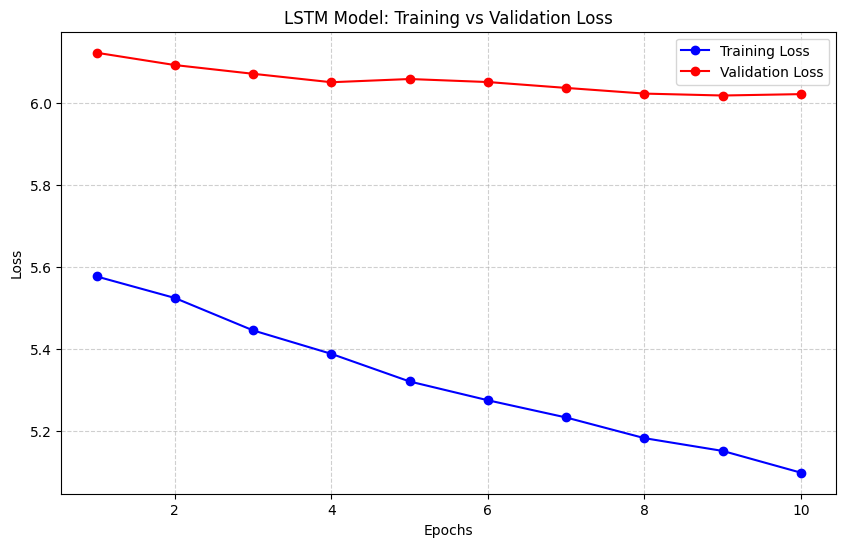

In [ ]:
# LSTM Model Training and Loss Plotting
epochs = 10
train_losses = []
val_losses = []

print("LSTM Model Training started...")
for epoch in range(epochs):
    model.train()
    epoch_loss = 0

    for src, trg in train_loader:
        src, trg = src.to(device), trg.to(device)
        optimizer.zero_grad()

        output = model(src, trg)
        # Reshape output for loss calculation
        output_dim = output.shape[-1]
        output = output[:, 1:, :].reshape(-1, output_dim)
        trg_target = trg[:, 1:].reshape(-1)

        loss = criterion(output, trg_target)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()

    # Calculate validation loss
    model.eval()
    val_loss = 0
    with torch.no_grad():
        for src, trg in dev_loader:
            src, trg = src.to(device), trg.to(device)
            output = model(src, trg, teacher_forcing_ratio=0.0)
            output_dim = output.shape[-1]
            output = output[:, 1:, :].reshape(-1, output_dim)
            trg_target = trg[:, 1:].reshape(-1)
            loss = criterion(output, trg_target)
            val_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    avg_val_loss = val_loss / len(dev_loader)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)
    print(f"Epoch {epoch+1:02d} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

# Plotting the Training and Validation Loss
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(train_losses) + 1), train_losses, label='Training Loss', marker='o', color='blue')
plt.plot(range(1, len(val_losses) + 1), val_losses, label='Validation Loss', marker='o', color='red')
plt.title('LSTM Model: Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()